<!-- The badge's branch, the setup cell's `git clone -b` and the folder it copies the case from must name the same branch. -->

> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/notebook-2-global-case/docs/notebooks/notebook_2/notebook_2.ipynb)
>
> The notebook opens with the results of an earlier run. To start from a clean notebook, choose Edit → Clear all outputs in Colab's menu first.
>
> Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# Session 2: Run a global case

> **Disclaimer**
>
> Navigate is an open-source analytical model intended for research and scenario analysis of maritime decarbonisation pathways. The model, its assumptions and any outputs are provided for illustrative and analytical purposes only.
>
> Model outputs depend on the assumptions selected by the user and should not be interpreted as forecasts, benchmarks, recommendations or commercially optimal outcomes, nor as legal, financial or investment advice.
>
> Users are responsible for selecting and adapting assumptions appropriate to their own circumstances and for exercising their own independent judgement when interpreting or relying on any model outputs.

Navigate ships a set of global **reference scenarios** under
`simulations/scenarios/`, which are full decks built and maintained by the Center. This session looks at how the decks differ and at the regulatory assumptions behind them, runs three of them (on a coarse time grid for fast solving, or year by year), and then changes their assumptions. Keep in mind that the simulations in this notebook are illustrative.

## The case


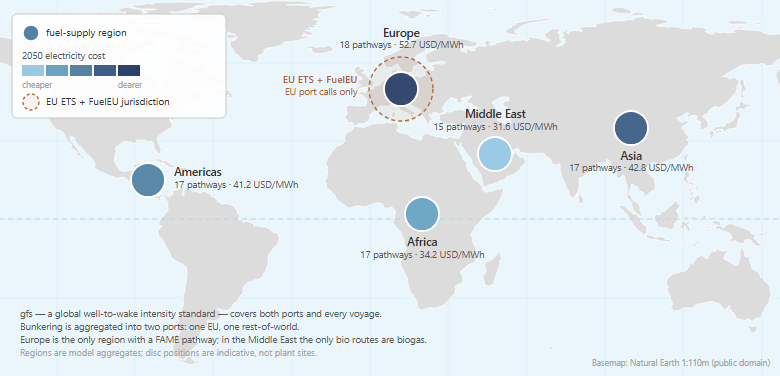

*The reference scenario's geography: five fuel-supply regions, the 2050 electricity
cost that feeds them, the production pathways each can host, and the EU jurisdiction
the ETS and FuelEU reach.*

In these decks, 23 fleets sail 23 routes that represent a global average profile, so geography does not really matter in this simulation.

## What you'll do

**Look at the scenarios.** See how each scenario is written as a Navigate simulation (a deck), and the regulatory assumptions behind them.

**Run the reference scenarios.** Solve them and compare their results.

**Sensitivity analysis.** Pick one of the reference scenarios, change some of the input parameters and see what happens.

**Global sensitivity analysis.** Let Horizon vary several input parameters at once, and see the range of results.

## STEP 1: Setup

Run the cell below on Colab or [locally](https://zerocarbonshipping.github.io/navigate-zcs/staging/notebooks/index.html#running-a-notebook-on-your-own-machine) to set up the Navigate model.

In [1]:
# @title Setup: run this cell once
ROOT = "/content"
# running locally: ROOT = any folder of your own, without spaces in its path, e.g. "/tmp/notebook"
%cd {ROOT}

import os
import shutil
import stat
# a copy from an earlier run goes, so the clone below is the current version (git's read-only files too)
if os.path.exists(f"{ROOT}/navigate-zcs"):
    shutil.rmtree(f"{ROOT}/navigate-zcs", onexc=lambda remove, path, _: (os.chmod(path, stat.S_IWRITE), remove(path)))
!git clone -q --depth 1 -b notebook-2-global-case https://github.com/zerocarbonshipping/navigate-zcs {ROOT}/navigate-zcs
%pip install -q {ROOT}/navigate-zcs \
    git+https://github.com/zerocarbonshipping/horizon-zcs@dev \
    git+https://github.com/zerocarbonshipping/lantern-zcs@dev
%env ASSUMPTIONS_DATA_DIR={ROOT}/navigate-zcs/assumptions

import sys

# this Python's folder first on PATH, so python, navigate and Horizon's runs use this install
os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"]

shutil.copytree(f"{ROOT}/navigate-zcs/docs/notebooks/notebook_2/global_case", f"{ROOT}/global_case", dirs_exist_ok=True)
%cd {ROOT}/global_case

# the tools the cells below call ----------------------------------------------------------------------
import contextlib
import html
import io
import json
import re
import subprocess
import threading
import time
import uuid
from pathlib import Path

from IPython.display import HTML, Pretty, display
import plotly.graph_objects as go
import lantern.config
import yaml
from importlib import resources
from lantern.server import make_server
from lantern.session import Session

# the levers every scenario holds, those of its regulations, and their reference values
COMMON = ["OIL_PRICE", "LNG_PRICE", "EFUEL_ELECTRICITY_PRICE", "BIOMASS_SHARE_FOR_SHIPPING",
          "BIOGENIC_CO2_AVAILABILITY", "PLANT_BUILD_LIMIT", "TRADE_GROWTH", "FREEZE_EFFICIENCY"]
EU = ["EU_ETS_PRICE", "FUELEU_TARGET", "FUELEU_PENALTY", "NO_EU_ETS", "NO_FUELEU", "EU_RULES_WORLDWIDE"]
STANDARD = ["GLOBAL_STANDARD_PENALTY", "GLOBAL_STANDARD_TARGET", "NO_GLOBAL_STANDARD"]
SCENARIOS = {
    "basecase_no_regulation": COMMON,
    "basecase_mid_regulation": COMMON + EU + STANDARD,
    "basecase_strong_regulation": COMMON + EU + STANDARD,
    "business_as_usual": COMMON + EU,
}
SWITCHES = ["NO_EU_ETS", "NO_FUELEU", "NO_GLOBAL_STANDARD", "EU_RULES_WORLDWIDE", "FREEZE_EFFICIENCY"]
REFERENCE = {lever: False if lever in SWITCHES else 1.0 for lever in COMMON + EU + STANDARD}

def deck_sets(scenario, levers, grid):
    # each lever as --set NAME=VALUE
    return " ".join(f"--set {name}={value}" for name, value in deck_values(scenario, levers, grid).items())

def deck_values(scenario, levers, grid):
    # each lever's value, as the scenario's deck names it; a switch picks a file, 1 or 0
    sets = {"GRID": grid}
    for lever, value in levers.items():
        if lever not in SCENARIOS[scenario]:
            if value != REFERENCE[lever]:
                print(f"{lever}: {scenario} has no such lever, so it has no effect.")
            continue
        if lever == "EU_RULES_WORLDWIDE":
            sets["EU_WORLDWIDE"] = 1 if value else 0
        elif lever in SWITCHES:
            deck_name = {"NO_EU_ETS": "EU_ETS", "NO_FUELEU": "FUELEU", "NO_GLOBAL_STANDARD": "GLOBAL_STANDARD",
                         "FREEZE_EFFICIENCY": "TECHNOLOGY_LIMIT"}[lever]
            sets[deck_name] = 0 if value else 1
        else:
            sets[lever] = value
    return sets

TITLES = {
    "session_emissions": "Well-to-wake emissions",
    "session_expenses": "Freight rate: what moving the cargo cost",
    "session_expenses_total": "Freight rate: what moving the cargo cost",
    "session_fuel_consumed": "Fuel consumed",
}

def show(*pages):
    # each page in a frame its plot fills, in one row that wraps on a narrow screen;
    # a page is plots/<run>/<plot>.html or plots/<plot>/<runs>.html
    figures = []
    for page in pages:
        path = Path(page)
        title = TITLES.get(path.stem) or TITLES[path.parent.name]
        with open(page, encoding="utf-8") as file:
            figures.append(figure(title, file.read()))
    display(HTML(f'<div style="display: flex; flex-wrap: wrap; gap: 8px">{"".join(figures)}</div>'))

def figure(title, page):
    # a plot of more than two panels, one per run, takes the whole row,
    # in a frame as tall as the grid of panels Lantern wrote into the page
    panels = len(set(re.findall(r'"xaxis":"(x\d*)"', page)))
    width = "100%" if panels > 2 else "280px"
    grid = re.search(r"max\(100vh - 16px, (\d+)px\)", page)
    height = max(420, int(grid[1]) + 16) if grid else 420
    page = page.replace("</body>", COMPACT + "</body>", 1)
    return (f'<figure style="flex: 1 1 {width}; margin: 0">'
            f'<figcaption style="font-weight: 600; margin-bottom: 4px">{title}</figcaption>'
            f'<iframe srcdoc="{html.escape(page)}" style="width: 100%; height: {height}px; border: 0"></iframe>'
            f'</figure>')

# in each page: narrower side margins than Plotly's 80 px, the legend clear of the year labels,
# and a year every ten on panels side by side
COMPACT = """<script>
window.addEventListener("load", () => {
  for (const plot of document.querySelectorAll(".js-plotly-plot")) {
    const update = {"margin.l": 56, "margin.r": 12, "legend.y": -0.16};
    const axes = Object.keys(plot.layout).filter(key => key.startsWith("xaxis"));
    if (axes.length > 1) for (const axis of axes) update[axis + ".dtick"] = "M120";
    Plotly.relayout(plot, update);
  }
});
</script>"""

def show_deck(tabs):
    # files of this case in tabs, coloured as the Navigate extension for VS Code does: its grammar,
    # in syntax/vscode/, gives the rules in order, and Lantern's theme the Center's colours
    from pygments import highlight
    from pygments.formatters import HtmlFormatter
    from pygments.lexer import RegexLexer
    from pygments.token import Comment, Keyword, Name, Number, Operator, String, Text

    grammar = json.loads(Path(f"{ROOT}/navigate-zcs/syntax/vscode/syntaxes/navigate.tmLanguage.json").read_text("utf-8"))
    scopes = {"comment": Comment, "keyword.control": Keyword, "storage.type": Keyword.Type,
              "constant.numeric": Number, "keyword.operator": Operator, "variable.other": Name.Variable}
    rules = []
    for ref in grammar["patterns"]:
        for rule in grammar["repository"][ref["include"].lstrip("#")]["patterns"]:
            if "match" in rule:
                rules.append((rule["match"], next(t for s, t in scopes.items() if rule["name"].startswith(s))))
            else:  # the one begin/end rule: a double-quoted string
                rules.append((r'"(?:\\.|[^"\\])*"', String))
    lexer = type("NavigateLexer", (RegexLexer,), {"tokens": {"root": rules + [(r"\w+|\s+|.", Text)]}})()

    colour = yaml.safe_load(resources.files("lantern").joinpath("theme.yaml").read_text("utf-8"))["swatches"]
    uid = f"deck-{uuid.uuid4().hex[:8]}"
    css = (f".{uid} > input {{display: none}}"
           f".{uid} > label {{display: inline-block; padding: .35em .9em; cursor: pointer;"
           f" opacity: .6; border-bottom: 2px solid transparent; font-family: sans-serif}}"
           f".{uid} > input:checked + label {{opacity: 1; border-bottom-color: currentColor}}"
           f".{uid} > div {{display: none; border-top: 1px solid rgba(128, 128, 128, .4)}}"
           f".{uid} .cap {{margin: .8em 0 .2em; font-family: sans-serif; font-size: .85em; opacity: .7}}"
           f".{uid} pre {{margin: 0; padding: .6em; overflow-x: auto; font-size: .85em;"
           f" background: rgba(128, 128, 128, .08)}}"
           # comments keep the text colour, so they read in Colab's light and dark themes
           f".{uid} pre .c {{font-style: italic; opacity: .75}}"
           f".{uid} pre .k {{color: {colour['red_4']}; font-weight: bold}}"
           f".{uid} pre .kt {{color: {colour['blue_6']}}}"
           f".{uid} pre .s {{color: {colour['orange_5']}}}"
           f".{uid} pre .m {{color: {colour['green_5']}}}"
           f".{uid} pre .nv {{color: {colour['purple_6']}; font-weight: bold}}")
    bar, panels, plain = [], [], []
    for i, (label, files) in enumerate(tabs.items()):
        checked = " checked" if i == 0 else ""
        bar.append(f'<input type="radio" name="{uid}" id="{uid}-{i}"{checked}>'
                   f'<label for="{uid}-{i}">{html.escape(label)}</label>')
        css += f"#{uid}-{i}:checked ~ .p{i} {{display: block}}"
        body = []
        for name in files:
            text = Path(name).read_text(encoding="utf-8")
            code = highlight(text, lexer, HtmlFormatter(nowrap=True))
            body.append(f'<div class="cap">{html.escape(name)}</div><pre>{code}</pre>')
            plain.append(f"# ---- {name} ----\n{text}")
        panels.append(f'<div class="p{i}">{"".join(body)}</div>')
    display({"text/html": f'<style>{css}</style><div class="{uid}">{"".join(bar + panels)}</div>',
             "text/plain": "\n".join(plain)}, raw=True)

def draw_global_standard():
    # the global fuel standard's limit in the two regulated basecases, and the penalty for missing it, read from
    # their regulation files; Navigate reads a forecast table as straight lines between its dates, flat after the last
    with contextlib.redirect_stdout(io.StringIO()):   # without its note of where plots.yaml is
        style = lantern.config.load_config().style
    plot = go.Figure()
    for row, (scenario, name) in enumerate((("basecase_mid_regulation", "mid regulation"),
                                            ("basecase_strong_regulation", "strong regulation"))):
        text = Path(f"includes/{scenario.removeprefix('basecase_')}.inc").read_text(encoding="utf-8")
        color = style.run_colors[scenario]
        dates, limits = forecast_table(text, "gfs_target_reduction")
        plot.add_scatter(x=dates, y=limits, mode="lines", name=name, line={"color": color, "width": 2})
        # the penalty, from the first date it is above zero
        dates, penalties = forecast_table(text, "gfs_remedial_unit")
        start, penalty = next((date, value) for date, value in zip(dates, penalties) if value > 0)
        plot.add_annotation(text=f"{name}: {limits[-1]:.1f} gCO2eq/MJ in 2050, "
                                 f"penalty {penalty:,.0f} USD/t from {start[:4]}",
                            xref="paper", yref="paper", x=0.01, y=0.04 + 0.09 * (1 - row),
                            xanchor="left", yanchor="bottom", showarrow=False, font={"color": color})
    # Lantern's layout, as its own plots have it
    plot.update_layout(template="plotly_white", hovermode="x unified", font=style.font, margin={"t": 16},
                       legend={"orientation": "h", "yanchor": "top", "y": -0.08, "x": 0})
    plot.update_xaxes(range=["2026-01-01", "2050-12-31"])
    plot.update_yaxes(title_text="gCO2eq/MJ", rangemode="tozero", hoverformat=",.3~r")
    page = plot.to_html(include_plotlyjs="cdn", config={"displaylogo": False},
                        default_height="max(100vh - 16px, 280px)")
    title = "Global fuel standard: the well-to-wake intensity limit every ship is held to"
    display(HTML(f'<div style="display: flex; flex-wrap: wrap; gap: 8px">{figure(title, page)}</div>'))

def forecast_table(text, forecast):
    # the dates and values of a forecast's table, times its multiplier, held flat to the end of 2050
    block = re.search(rf'Forecast "{forecast}" {{(.*?)\n}}', text, re.S)[1]
    multiplier = re.search(r"Multiplier = ([\d.]+)", block)
    scale = float(multiplier[1]) if multiplier else 1.0
    rows = re.findall(r'"(\d\d)-(\d\d)-(\d{4})",\s*([\d.]+);', block)
    dates = [f"{year}-{month}-{day}" for day, month, year, _ in rows] + ["2050-12-31"]
    values = [float(value) * scale for *_, value in rows]
    return dates, values + values[-1:]

BASECASES = ["basecase_no_regulation", "basecase_mid_regulation", "basecase_strong_regulation"]
PLOTS = ["session_emissions", "session_expenses_total", "session_fuel_consumed"]
solved = {}  # the time grid STEP 3 solved on, which STEP 4 keeps

def run_references(full_resolution, include_business_as_usual):
    # solve the reference scenarios all at once, on the coarse grid or year by year; each one's results go to
    # reference/<grid>/parquets/<scenario>.parquet and what it prints to reference/<grid>/<scenario>.txt
    grid = "yearly" if full_resolution else "coarse"
    scenarios = BASECASES + (["business_as_usual"] if include_business_as_usual else [])
    folder = Path("reference") / grid
    folder.mkdir(parents=True, exist_ok=True)
    env = dict(os.environ, PYTHONUNBUFFERED="1")  # so each run's year reaches its console log as it goes
    processes, logs, started = {}, {}, time.time()
    try:
        for scenario in scenarios:
            logs[scenario] = open(folder / f"{scenario}.txt", "w", encoding="utf-8")
            command = [sys.executable, "-m", "navigate", f"{scenario}.unc", "--name", scenario,
                       "--output-dir", str(folder), *deck_sets(scenario, REFERENCE, grid).split()]
            processes[scenario] = subprocess.Popen(command, stdout=logs[scenario], stderr=subprocess.STDOUT, env=env)

        def progress(scenario):
            code = processes[scenario].poll()
            if code is not None:
                return "done" if code == 0 else f"FAILED (exit {code}), see {folder.as_posix()}/{scenario}.txt"
            years = re.findall(r"^Date: (\d{4})", (folder / f"{scenario}.txt").read_text("utf-8", "replace"), re.M)
            return f"solving {years[-1]}" if years else "setting up the model"

        def status():
            minutes, seconds = divmod(int(time.time() - started), 60)
            lines = [f"  {scenario:28} {progress(scenario)}" for scenario in scenarios]
            return Pretty("\n".join(lines) + f"\n\n{minutes} min {seconds:02d} s elapsed")

        board = display(status(), display_id=True)
        while any(process.poll() is None for process in processes.values()):
            time.sleep(10)
            board.update(status())
        board.update(status())
    finally:
        for log in logs.values():
            log.close()
    assert all(process.returncode == 0 for process in processes.values()), "a scenario failed, see above"
    solved["grid"] = grid

    # draw them against each other, show the plots, and link them to Lantern's viewer
    draw([folder / "parquets" / f"{scenario}.parquet" for scenario in scenarios])

def run_scenario(scenario, name, levers, reset):
    # solve your scenario, a change of one of STEP 3's, on STEP 3's grid; its results go to
    # sensitivities/<grid>/<scenario>/parquets/<name>.parquet, next to the runs of that scenario before it unless reset
    assert "grid" in solved, "solve the reference scenarios in STEP 3 first"
    assert scenario in SCENARIOS, f"choose SCENARIO from {list(SCENARIOS)}"
    grid = solved["grid"]
    reference = Path("reference") / grid / "parquets" / f"{scenario}.parquet"
    assert reference.exists(), f"{scenario} was not solved in STEP 3: set INCLUDE_BUSINESS_AS_USUAL = True there"
    folder = Path("sensitivities") / grid / scenario
    if reset:
        shutil.rmtree(folder, ignore_errors=True)
    sets = deck_sets(scenario, levers, grid)
    !python -m navigate {scenario}.unc --name {name} --output-dir {folder} {sets}

    # draw every run, in the order they were run, against the reference, and link them to Lantern's viewer
    runs_so_far = sorted((folder / "parquets").glob("*.parquet"), key=lambda path: path.stat().st_mtime)
    draw([reference, *runs_so_far])

# the levers whose high end lowers the emissions: sample 2 of a study takes them at their highest
EMISSIONS_LOW_AT_MAXIMUM = {"OIL_PRICE", "LNG_PRICE", "EU_ETS_PRICE", "FUELEU_PENALTY", "GLOBAL_STANDARD_PENALTY",
                            "BIOMASS_SHARE_FOR_SHIPPING", "BIOGENIC_CO2_AVAILABILITY", "PLANT_BUILD_LIMIT"}

def run_study(scenario, name, ranges, switches, all_on, samples, reset):
    # write the study of one of STEP 3's scenarios, on STEP 3's grid, to studies/<grid>/<scenario>/<name>.hor and
    # check it. Sample 1 takes every lever at its most likely value, sample 2 at the end that lowers the emissions,
    # sample 3 at the other end; the rest are a Latin hypercube.
    assert "grid" in solved, "solve the reference scenarios in STEP 3 first"
    assert scenario in SCENARIOS, f"choose SCENARIO from {list(SCENARIOS)}"
    grid = solved["grid"]
    reference = Path("reference") / grid / "parquets" / f"{scenario}.parquet"
    assert reference.exists(), f"{scenario} was not solved in STEP 3: set INCLUDE_BUSINESS_AS_USUAL = True there"
    folder = Path("studies") / grid / scenario
    if reset:
        shutil.rmtree(folder, ignore_errors=True)

    # what every run of the study keeps: the time grid, the switches, and the levers that are off
    fixed = deck_values(scenario, {**{lever: 1.0 for lever in ranges}, **switches}, grid)
    blocks, absent = [], []
    for lever, (on, lowest, likely, highest) in ranges.items():
        if lever not in SCENARIOS[scenario]:
            absent += [lever] if on or all_on else []
            continue
        del fixed[lever]
        options = ["emissions_low = MAXIMUM"] if lever in EMISSIONS_LOW_AT_MAXIMUM else []
        if not (on or all_on):
            options += ["default = 1.0", "active = FALSE"]
        braces = f" {{ {', '.join(options)} }}" if options else ""
        blocks.append(f'ContinuousParameter "{lever}" = TRIANGULAR({lowest}, {likely}, {highest}){braces}')
    if absent:
        print(f"{scenario} has no {', '.join(absent)}, so the study leaves them out.")
    blocks += [f'ScenarioParameter "{deck_name}" {{ values = ["{value}"], default = "{value}", active = FALSE }}'
               for deck_name, value in fixed.items()]
    study = "\n".join([
        "Horizon {",
        f'    UncFilePath = "../../../{scenario}.unc"',
        f'    OutputPath = "{name}"',
        f"    NumberOfSamples = {samples}",
        "    SamplingMethod = LHS",
        "    RandomSeed = 42",
        "}",
    ])
    hor = (folder / f"{name}.hor").as_posix()
    folder.mkdir(parents=True, exist_ok=True)
    with open(hor, "w", encoding="utf-8") as file:
        file.write("\n".join(blocks) + "\n\n" + study + "\n")
    !python -m horizon check {hor}

    # run the study, one solve per sample, and gather the runs into studies/<grid>/<scenario>/<name>/
    !python -m horizon run {hor} && python -m horizon collect {hor}
    assert (folder / name / f"{name}.parquet").exists(), "the study did not run to the end: see Horizon's messages above"

    # draw every study of this scenario so far, in the order they were run, against the reference and show the plots
    studies_so_far = sorted((path for path in folder.glob("*/*.parquet") if path.stem == path.parent.name),
                            key=lambda path: path.stat().st_mtime)
    names = [path.stem for path in studies_so_far]
    runs = [scenario, *(f"{study}/{study}" for study in names)]
    plots = ["session_emissions", "session_expenses_total"]
    files = " ".join(path.as_posix() for path in [reference, *studies_so_far])
    picks = " ".join(f'--plot "{plot}[{",".join(runs)}]"' for plot in plots)
    !python -m lantern {files} {picks}

    show(*(f"plots/{plot}/{'+'.join([scenario, *names])}.html" for plot in plots))
    open_viewer([reference, *studies_so_far])

def draw(files):
    # the session's plots of these runs, side by side, then every plot Lantern has in its viewer
    runs = [path.stem for path in files]
    picks = " ".join(f'--plot "{plot}[{",".join(runs)}]"' for plot in PLOTS)
    paths = " ".join(path.as_posix() for path in files)
    !python -m lantern {paths} {picks}
    show(*(f"plots/{plot}/{'+'.join(runs)}.html" for plot in PLOTS))
    open_viewer(files)

lantern_server = None

def open_viewer(files):
    global lantern_server
    # every run so far in Lantern's own viewer, in a new tab. The viewer runs inside this notebook,
    # so the link works while the notebook is connected; running the cell again reloads the runs.
    port = 0  # any free port; running the cell again replaces the viewer on the same port
    if lantern_server is not None:
        port = lantern_server.server_address[1]
        lantern_server.shutdown()
        lantern_server.server_close()
    lantern.config.PLOTS_FILES = (viewer_catalogue(),)  # the viewer's catalogue; the plot cells keep plots.yaml
    lantern_server = make_server(Session(files), port)
    threading.Thread(target=lantern_server.serve_forever, daemon=True).start()
    port = lantern_server.server_address[1]

    try:
        from google.colab import output
    except ImportError:  # Jupyter or VS Code on your own machine: the browser reaches the viewer directly
        display(HTML(f'<a href="http://127.0.0.1:{port}/" target="_blank">Click here to see more plots</a>'))
        return

    output.serve_kernel_port_as_window(port, anchor_text="Click here to see more plots", skip_warning=True)
    # Firefox keeps Colab's sign-in from the new tab, so offer the viewer inside the notebook too,
    # in a frame under the line, through Colab's proxy as serve_kernel_port_as_iframe does
    display(HTML(OPEN_HERE.replace("PORT", str(port))))

def viewer_catalogue():
    # every plot Lantern has, after the workshop's own: Lantern's catalogue with this case's
    # plots.yaml on top, written to viewer/plots.yaml, which only the viewer reads
    own = yaml.safe_load(Path("plots.yaml").read_text("utf-8"))
    shipped = yaml.safe_load(resources.files("lantern").joinpath("plots.yaml").read_text("utf-8"))
    catalogue = {key: shipped.pop(key, None) or {} for key in ("customize_runs", "labels", "theme")}
    catalogue["customize_runs"].update(own.pop("customize_runs", {}))
    catalogue.update(own)      # the workshop's plots first
    catalogue.update(shipped)  # then all of Lantern's
    path = Path("viewer/plots.yaml")
    path.parent.mkdir(exist_ok=True)
    path.write_text(yaml.safe_dump(catalogue, sort_keys=False, allow_unicode=True), "utf-8")
    return path.resolve()

OPEN_HERE = """<div style="font-size: 0.85em; margin-top: 4px">
If the page does not open in Firefox, use Chrome or Edge, or
<a href="#" onclick="openHere(this); return false;">open it here</a>.
</div>
<script>
async function openHere(link) {
  const url = await google.colab.kernel.proxyPort(PORT, {cache: false});
  const frame = document.createElement("iframe");
  frame.src = url;
  frame.style = "width: 100%; height: 800px; border: 0";
  link.parentElement.after(frame);
}
</script>"""

/content


Note: you may need to restart the kernel to use updated packages.
env: ASSUMPTIONS_DATA_DIR=/content/navigate-zcs/assumptions


/content/global_case


---

## STEP 2: Check the different scenarios

The Center maintains four reference scenarios in `simulations/scenarios/`.

The three basecases share the same fleet, fuel and port assumptions and differ only in regulation. `business_as_usual` applies only the EU ETS and FuelEU and also includes the domestic fleet:

| scenario | regulation |
|---|---|
| `basecase_no_regulation` | nothing at all - fuel chosen on cost |
| `basecase_mid_regulation` | EU ETS + FuelEU + a moderate global fuel standard |
| `basecase_strong_regulation` | EU ETS + FuelEU + a strict global fuel standard |
| `business_as_usual` | EU ETS + FuelEU |

In `business_as_usual`, each ship class is split into an international and a domestic fleet: about half the ships by number are domestic, mostly tugs, ferries, offshore and other small vessels. The two fleets have the same ships and differ only in where they sail. A quarter of the domestic voyages stay inside Europe, where the EU ETS and FuelEU cover them in full, against under 5 % of the international ones.

Run the next cell to see how the scenarios are written in Navigate's input format: one deck per scenario, one tab each. The `%NAME%` placeholders are the levers and switches of the sensitivity analyses in STEPs 4 and 5. On Colab, the files can be found in the Files panel on the left (the 📁 folder icon), under `global_case/` (the decks) and `global_case/includes/`.

In [2]:
show_deck({
    "no regulation": ["basecase_no_regulation.unc"],
    "mid regulation": ["basecase_mid_regulation.unc", "includes/mid_regulation.inc"],
    "strong regulation": ["basecase_strong_regulation.unc", "includes/strong_regulation.inc"],
    "business as usual": ["business_as_usual.unc"],
})

# ---- basecase_no_regulation.unc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# BASECASE_NO_REGULATION - simulations/scenarios/basecase_no_regulation, on the coarse grid
# (--set GRID=coarse) or year by year (--set GRID=yearly), with Session 2's
# levers as %NAME% placeholders: every multiplier and switch at 1 gives the
# scenario itself.

DEFINE {
    Load DefaultModelDefinition

    # fleets
    Load DefaultFleet

    # voyages
    Load DefaultPort

    # fuels
    Load DefaultEmission
    Load DefaultFeedstock
    Load DefaultFuel
    Load DefaultProducer
    Load DefaultPlant
    Load DefaultRegion
    Load DefaultSource
    Load DefaultTransport

    # calibration
    Load DefaultCalibration

    # levers
    Include "includes/levers.inc"
}

EVENTS {
    Load DefaultConverterAvailable
    Include "includes/time_steps_%GRID%.inc"
}

# ---- basecase_mid_regulation.unc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# BASECASE_MID_REGULATION - simulations/scenarios/basecase_mid_regulation, on the coarse grid
# (--set GRID=coarse) or year by year (--set GRID=yearly), with Session 2's
# levers as %NAME% placeholders: every multiplier and switch at 1 gives the
# scenario itself.

DEFINE {
    Load DefaultModelDefinition

    # fleets
    Load DefaultFleet

    # voyages
    Load DefaultPort

    # fuels
    Load DefaultEmission
    Load DefaultFeedstock
    Load DefaultFuel
    Load DefaultProducer
    Load DefaultPlant
    Load DefaultRegion
    Load DefaultSource
    Load DefaultTransport

    # regulations
    Load DefaultRegulation
    Include "includes/mid_regulation.inc"

    # calibration
    Load DefaultCalibration

    # levers
    Include "includes/levers.inc"
    Include "includes/eu_levers.inc"
    Include "includes/global_standard_levers.inc"

    # switches: 0 or 1 picks a file
    Include "includes/eu_ets_%EU_ETS%.inc"
    Include "includes/fuel_eu_%FUELEU%.inc"
    Include "includes/eu_worldwide_%EU_WORLDWIDE%.inc"
    Include "includes/global_standard_%GLOBAL_STANDARD%.inc"
}

EVENTS {
    Load DefaultConverterAvailable
    Include "includes/time_steps_%GRID%.inc"
}

# ---- includes/mid_regulation.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# A copy of simulations/scenarios/0_includes/mid_regulation.inc.

Regulation "gfs" {
	Measure = INTENSITY
	Scheme = FLEXIBLE

	Scope = WTW
	IncludeSlip = TRUE

	Emissions = Emission("*")
	Fuels = Fuel("*")
		
	Jurisdiction = [Port("port_global"), Port("port_europe")]
	
	RemedialCost = Forecast("gfs_remedial_unit")
	
	set_vessel_threshold("*", Forecast("gfs_target_reduction"))
	
	set_include_vessel("*", TRUE)
}


Forecast "gfs_target_reduction" {
	Table = [
		"01-01-2025",	1.00;
		"31-12-2027",	1.00;
		"01-01-2028",	0.96;
		"01-01-2029",	0.94;
		"01-01-2030",	0.95;
		"01-01-2035",	0.75;
		"01-01-2050",	0.30;
	]
	
	Multiplier = 93.3
	Extrapolate = FLAT
}

Forecast "gfs_remedial_unit" {
	Table = [
		"01-01-2025",	0;
		"31-12-2027",	0;
		"01-01-2028",	300;
		"01-01-2050",	300;
	]
	
	Extrapolate = FLAT
}

# ---- basecase_strong_regulation.unc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# BASECASE_STRONG_REGULATION - simulations/scenarios/basecase_strong_regulation, on the coarse grid
# (--set GRID=coarse) or year by year (--set GRID=yearly), with Session 2's
# levers as %NAME% placeholders: every multiplier and switch at 1 gives the
# scenario itself.

DEFINE {
    Load DefaultModelDefinition

    # fleets
    Load DefaultFleet

    # voyages
    Load DefaultPort

    # fuels
    Load DefaultEmission
    Load DefaultFeedstock
    Load DefaultFuel
    Load DefaultProducer
    Load DefaultPlant
    Load DefaultRegion
   

"Global fuel standard" is a limit on the well-to-wake carbon intensity of the energy a ship
uses, applied worldwide: a ship above the limit pays, a ship
below it earns surplus units it can sell. The decks call it `gfs`.

`gfs_target_reduction` is the well-to-wake GHG intensity limit every vessel is measured against, and
`gfs_remedial_unit` is the penalty for missing it. Both are defined per scenario in `includes/mid_regulation.inc` and `includes/strong_regulation.inc`, shown in the tabs above (copies of `simulations/scenarios/0_includes/`).

Run the next cell to draw the limit in the two scenarios that have one, with the penalty for missing it.

In [3]:
draw_global_standard()

---

## STEP 3: Run the reference scenarios and compare them

Run the cell below to solve the scenarios described in STEP 2, then compare their results with [Lantern](https://github.com/zerocarbonshipping/lantern-zcs/tree/dev), our tool for plotting Navigate's results. Hover over a plot to read its values, or drag to zoom. The link under the plots opens Lantern's full viewer.

The switch `INCLUDE_BUSINESS_AS_USUAL` adds `business_as_usual`; it is off by default, because it takes longer to solve.

By default, the scenarios are solved on 8 time steps instead of 25, to speed up solving. Set `FULL_RESOLUTION = True` to solve the scenarios year by year instead. Since this takes a while (5 to 15 min, depending on the machine), you can go for a coffee or tea, or take a nap, in the meantime.

Running the simulation year by year instead of every four years changes the results only slightly. The following table shows some of the differences for `basecase_mid_regulation`:

| mid regulation | yearly | coarse |
|---|---|---|
| emissions in 2050 | 663 Mt/yr | 668 Mt/yr |
| alternative fuels in 2050 | 49.5 % | 50.1 % |

In [4]:
# Solve the reference scenarios, all at once, then compare them
FULL_RESOLUTION = False            # True: year by year, 25 time steps instead of 8 (5 to 15 minutes)
INCLUDE_BUSINESS_AS_USUAL = False  # True: business_as_usual as well
# Off by default: business_as_usual is quite different from the three basecases. It splits each ship
# class into an international and a domestic fleet that sail differently (see STEP 2), so its results
# do not differ from theirs by regulation alone. It is also the slowest, with twice as many fleets.

run_references(FULL_RESOLUTION, INCLUDE_BUSINESS_AS_USUAL)

  basecase_no_regulation       done
  basecase_mid_regulation      done
  basecase_strong_regulation   done

1 min 10 s elapsed

Plots from /content/global_case/plots.yaml
Loaded basecase_no_regulation: 1 run(s), 4 of 4 plots with data
Loaded basecase_mid_regulation: 1 run(s), 4 of 4 plots with data
Loaded basecase_strong_regulation: 1 run(s), 4 of 4 plots with data
Wrote 3 plots to plots
plots/session_emissions/basecase_no_regulation+basecase_mid_regulation+basecase_strong_regulation.html
plots/session_expenses_total/basecase_no_regulation+basecase_mid_regulation+basecase_strong_regulation.html
plots/session_fuel_consumed/basecase_no_regulation+basecase_mid_regulation+basecase_strong_regulation.html


Plots from /content/global_case/viewer/plots.yaml


Loaded basecase_no_regulation: 1 run(s), 51 of 60 plots with data


Loaded basecase_mid_regulation: 1 run(s), 54 of 60 plots with data


Loaded basecase_strong_regulation: 1 run(s), 54 of 60 plots with data


---

## STEP 4: Sensitivity analysis

Pick one of the reference scenarios of STEP 3 with `SCENARIO`, then change some of its input values to see what changes in the results. Your runs are solved on the same time grid as STEP 3: with `FULL_RESOLUTION = True`, each one takes a few minutes.

All the levers we prepared are multipliers, so `1.0` keeps the original assumption, except five that are switches:

- **`NO_EU_ETS`**, **`NO_FUELEU`** and **`NO_GLOBAL_STANDARD`** each take one
  regulation out and keep the others, to see what that one adds. The levers of
  a regulation taken out then have no effect.
- **`EU_RULES_WORLDWIDE`** applies the EU ETS and FuelEU to every voyage, not only
  to the share that touches Europe.
- **`FREEZE_EFFICIENCY`** stops anything further from being fitted, on newbuilds as
  well as on retrofits.

The spans indicated in the cell below are a suggestion, not a limit.

**GAME**: Find out which scenario (realistic?) leads to the lowest emissions and transport costs by 2050.

In [ ]:
# YOUR SCENARIO: pick a reference scenario of STEP 3, set the levers, then run this cell
SCENARIO = "basecase_mid_regulation"  # one of the scenarios solved in STEP 3:
                                      # "basecase_mid_regulation", "basecase_no_regulation",
                                      # "basecase_strong_regulation", or "business_as_usual" if STEP 3 included it
NAME = "your_scenario"  # a new name, without spaces, adds a run to the plots
RESET = False           # True: clear the runs drawn so far

#                                      suggested span  what 1.0 means in basecase_mid_regulation
LEVERS = {
    "OIL_PRICE": 2.0,                   #  0.6 - 2.0       485 USD/t, flat to 2050
    "LNG_PRICE": 1.0,                   #  0.6 - 2.0       436 USD/t, flat to 2050
    "EU_ETS_PRICE": 1.0,                #  0.5 - 3.0       126 USD/t in 2026, 417 by 2050
    "FUELEU_TARGET": 1.0,               #  0.3 - 1.2       88.6 gCO2eq/MJ in 2026, 18.2 by 2050; under 1.0 is STRICTER
    "FUELEU_PENALTY": 1.0,              #  1.0 - 5.0       760 USD/t of excess emission, flat
    "GLOBAL_STANDARD_PENALTY": 1.0,     #  0.0 - 5.0       0 until 2028, then 300 USD/t of excess (strong: 800)
    "GLOBAL_STANDARD_TARGET": 1.0,      #  0.5 - 1.2       93.3 gCO2eq/MJ in 2026, 28.0 by 2050 (strong: 0); under 1.0 is STRICTER
    "EFUEL_ELECTRICITY_PRICE": 1.0,     #  0.6 - 1.4       58-88 USD/MWh in 2026, by region
    "BIOMASS_SHARE_FOR_SHIPPING": 1.0,  #  0.5 - 3.0       2-50 % of the pool, by feedstock
    "BIOGENIC_CO2_AVAILABILITY": 1.0,   #  0.5 - 2.0       92 Mt/yr pool in 2026, 350 by 2050 (shipping's share: 50 %)
    "PLANT_BUILD_LIMIT": 1.0,           #  0.5 - 3.0       7.1 plants a year in 2026, rising (not bio-fuel plants)
    "TRADE_GROWTH": 1.0,                #  0.0 - 2.0       0.3-4.7 %/yr in 2026, by segment;
                                        #                  1.0 = each segment's own growth; 0.0 = trade stays
                                        #                  at its 2026 volume; -1.0 = it shrinks as fast as it grew

    # the five switches: True or False
    "NO_EU_ETS": False,                 #  True = EU ETS taken out; FuelEU and the fuel standard stay
    "NO_FUELEU": False,                 #  True = FuelEU taken out; EU ETS and the fuel standard stay
    "NO_GLOBAL_STANDARD": False,        #  True = the global fuel standard taken out; the EU rules stay
    "EU_RULES_WORLDWIDE": False,        #  True = EU ETS and FuelEU apply to every voyage, not only Europe's
    "FREEZE_EFFICIENCY": False,         #  True = nothing further gets fitted, newbuild or retrofit
}
# Every number down to TRADE_GROWTH is a multiplier on what the deck already says, so 1.0 is the
# reference. As an example, BIOMASS_SHARE_FOR_SHIPPING is set to 2.0: shipping gets twice the
# biomass. Set it back to 1.0 to start from the reference.
#
# basecase_no_regulation has no EU ETS, FuelEU or global fuel standard, so EU_ETS_PRICE, the two
# FUELEU levers, the two GLOBAL_STANDARD levers and the regulation switches change nothing there.
# business_as_usual has no global fuel standard, so its two levers and NO_GLOBAL_STANDARD change
# nothing there.

# solve your scenario as a change of SCENARIO, on STEP 3's time grid, draw it with the runs before it,
# and link them to Lantern's viewer
run_scenario(SCENARIO, NAME, LEVERS, RESET)

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”
            |    |    |                                  .oO
           )_)  )_)  )_)                             __/___                  _    _
          )___))___))___)\                     _____/______|              __|_|__|_|__
         )____)____)_____)\\           _______/_____\_______\_____      _|____________|__
       _____|____|____|____\\\__       \              < < <       |    |o o o o o o o o /
~~~~~~~\                   /~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
        Â´Â´Â´Â´Â´Â´Â´Â

Plots from /content/global_case/plots.yaml
Loaded basecase_mid_regulation: 1 run(s), 4 of 4 plots with data
Loaded your_scenario: 1 run(s), 4 of 4 plots with data
Wrote 3 plots to plots
plots/session_emissions/basecase_mid_regulation+your_scenario.html
plots/session_expenses_total/basecase_mid_regulation+your_scenario.html
plots/session_fuel_consumed/basecase_mid_regulation+your_scenario.html


Plots from /content/global_case/viewer/plots.yaml


Loaded basecase_mid_regulation: 1 run(s), 54 of 60 plots with data


Loaded your_scenario: 1 run(s), 54 of 60 plots with data


---

## STEP 5: Global sensitivity analysis with Horizon

STEP 4 solves one scenario at a time. [Horizon](https://github.com/zerocarbonshipping/horizon-zcs/tree/dev), the tool we use for global sensitivity analysis in our own work, moves several levers at once: it draws a value for each lever from its range and solves the case once per draw.

In the cell below, pick a reference scenario with `SCENARIO`, as in STEP 4. Then turn levers on and set their ranges. Only `OIL_PRICE` is on to start with; the others stay at the reference. Run the cell: it runs fifteen simulations by default, on the time grid of STEP 3. The number of simulations can be changed with `SAMPLES`. Each new `STUDY` name adds a study to the plots, and `RESET` clears them; two or three studies at a time stay readable.

Horizon solves as many simulations at once as the machine has processors: on the coarse grid, a study of fifteen takes a few minutes. With `FULL_RESOLUTION = True` in STEP 3, it takes much longer.

Each plot shows the reference in its colour of STEP 3 and each study in a colour of its own:

- the shaded band: in each year, the middle 90 % of the runs, from the 5th to the 95th percentile;
- the dashed line: the median of the runs, year by year;
- the solid line: the one run that stays closest to that median over the years.

In [ ]:
# THE STUDY: pick a reference scenario of STEP 3, turn levers on and set their ranges, then run this cell
SCENARIO = "basecase_mid_regulation"  # one of the scenarios solved in STEP 3, as in STEP 4
STUDY = "oil_price"  # a new name, without spaces, adds a study to the plots
RESET = False        # True: clear the studies drawn so far
ALL_ON = False       # True: every lever on, whatever its "on" column says
SAMPLES = 15         # number of simulations

#                                  on     lowest  most likely  highest   what 1.0 means in basecase_mid_regulation
RANGES = {
    "OIL_PRICE":                  (True,  0.6,    1.0,         2.0),   # 485 USD/t, flat to 2050
    "LNG_PRICE":                  (False, 0.6,    1.0,         2.0),   # 436 USD/t, flat to 2050
    "EU_ETS_PRICE":               (False, 0.5,    1.0,         3.0),   # 126 USD/t in 2026, 417 by 2050
    "FUELEU_TARGET":              (False, 0.3,    1.0,         1.2),   # 88.6 gCO2eq/MJ in 2026, 18.2 by 2050; under 1.0 is STRICTER
    "FUELEU_PENALTY":             (False, 1.0,    1.0,         5.0),   # 760 USD/t of excess emission, flat
    "GLOBAL_STANDARD_PENALTY":    (False, 0.0,    1.0,         5.0),   # 0 until 2028, then 300 USD/t of excess (strong: 800)
    "GLOBAL_STANDARD_TARGET":     (False, 0.5,    1.0,         1.2),   # 93.3 gCO2eq/MJ in 2026, 28.0 by 2050 (strong: 0); under 1.0 is STRICTER
    "EFUEL_ELECTRICITY_PRICE":    (False, 0.6,    1.0,         1.4),   # 58-88 USD/MWh in 2026, by region
    "BIOMASS_SHARE_FOR_SHIPPING": (False, 0.5,    1.0,         3.0),   # 2-50 % of the pool, by feedstock
    "BIOGENIC_CO2_AVAILABILITY":  (False, 0.5,    1.0,         2.0),   # 92 Mt/yr pool in 2026, 350 by 2050
    "PLANT_BUILD_LIMIT":          (False, 0.5,    1.0,         3.0),   # 7.1 plants a year in 2026, rising (not bio-fuel plants)
    "TRADE_GROWTH":               (False, 0.0,    1.0,         2.0),   # 0.3-4.7 %/yr in 2026, by segment
}
# A lever that is off stays at 1.0. A lever that is on is drawn from a triangular distribution.
# A lever the scenario does not have (see STEP 4) is left out of its study.

# the five switches, the same for every run of the study: True or False
SWITCHES = {
    "NO_EU_ETS": False,           # True = EU ETS taken out; FuelEU and the fuel standard stay
    "NO_FUELEU": False,           # True = FuelEU taken out; EU ETS and the fuel standard stay
    "NO_GLOBAL_STANDARD": False,  # True = the global fuel standard taken out; the EU rules stay
    "EU_RULES_WORLDWIDE": False,  # True = EU ETS and FuelEU apply to every voyage, not only Europe's
    "FREEZE_EFFICIENCY": False,   # True = nothing further gets fitted, newbuild or retrofit
}

# write the study, run it with Horizon on STEP 3's time grid, and draw it with the studies before it,
# against the reference
run_study(SCENARIO, STUDY, RANGES, SWITCHES, ALL_ON, SAMPLES, RESET)

### Advanced sensitivities

The levers proposed in the previous sections are only a few examples of what can be changed in the model. Sensitivities on other parameters, or simulations of your own, can be done by:

- editing the deck `docs/notebooks/notebook_2/global_case/basecase_mid_regulation.unc` itself (easier with a [local installation](https://zerocarbonshipping.github.io/navigate-zcs/tutorials/getting_started.html));
- making fuller use of our [Horizon-zcs](https://github.com/zerocarbonshipping/horizon-zcs/tree/dev) tool for global sensitivity analysis. STEP 5 writes each of its studies to a `.hor` file, `studies/<grid>/<scenario>/<study>.hor` in the case folder (on Colab: the Files panel on the left, under `global_case/studies/`), which you can use for inspiration.

## Regenerate this case yourself

The full prompt that rebuilds this case with an AI coding assistant on your own machine is in the prompt bank, as *Session 2's reference scenario*. [Session 5: Build your own case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/05-build-your-own-case.ipynb#example-b) shows how to use it, and how to build a case of your own.

## Workshop sessions

**Next: [Session 3: How a Navigate model is built](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/03-how-a-navigate-model-is-built.ipynb)**

Each link opens the notebook in Google Colab, in a fresh session, so run it
from the top.

1. [Run a simple case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/01-run-a-simple-case.ipynb)
2. **Run a global case** (this session)
3. [How a Navigate model is built](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/03-how-a-navigate-model-is-built.ipynb)
4. [How Navigate solves](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb)
5. [Build your own case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/05-build-your-own-case.ipynb)